# 03 · Unión y limpieza: la tabla del niño (2024 y 2025)

**Responsable:** Magno Luque · **Proyecto:** YAWAR (Hackathon FACI 2026, UPCH)

## Para qué sirve este cuaderno
Construye **una tabla limpia por año, con una fila por niño**, lista para el modelo (Jose) y para las cifras ponderadas (cuaderno 04). Hace cuatro cosas, en este orden:

1. **Une** las tablas de ENDES y documenta cuántos niños se pierden en cada unión.
2. **Limpia:** traduce los códigos ("1 = sí", "2 = no", "8 = no sabe") a valores claros y convierte "no sabe" y vacíos en dato faltante.
3. **Revisa la coherencia** de los datos con varias comprobaciones.
4. **Registra cuántos niños quedan fuera en cada paso** hasta llegar a la cohorte preliminar.

## Reglas que seguimos (para que el trabajo sea defendible)
- **Nunca se borra un niño sin dejar registro.** Los niños que no entran a la cohorte siguen en la tabla, con una marca (`en_cohorte_modelo`), y el recuento de exclusiones se muestra en la sección 5.
- **"No sabe" (8) y vacío no se convierten en "no".** Quedan como faltante. Son muy pocos casos, pero tratarlos como "no" cambiaría la etiqueta del modelo sin base.
- **La edad en meses es la calculada** (fecha de entrevista − fecha de nacimiento), con la edad directa `HW1` como control. Decisión registrada en `docs/registro_decisiones_analisis.md`.
- **Las presentaciones de hierro se emparejan por su nombre, no por su letra** (en "recibió" y en "tomó" las letras B y C están cruzadas; ver cuaderno 01).
- **Los factores de expansión se guardan tal como vienen.** Se guardan los dos que usa INEI: el factor **mujer** (`V005`) y el factor **hogar** (`HV005`). Según la ficha técnica, el peso se obtiene dividiendo entre 1 000 000 y el factor hogar es el que corresponde a anemia en menores de 5 años. Esa división se hace en el cuaderno 04; aquí no se toca.

## Qué produce
- `datos_procesados/tabla_nino_2024.csv` y `tabla_nino_2025.csv` (**no se suben al repositorio**: contienen microdatos de ENDES; cada compañero los genera ejecutando este cuaderno).
- `docs/diccionario_tabla_nino.md`: el diccionario de cada columna, generado por este mismo cuaderno.

In [1]:
import sys
sys.path.insert(0, ".")

import pandas as pd
from rutas import RAIZ, leer

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

SALIDA = RAIZ / "datos_procesados"
DOCS = RAIZ / "docs"

## 1. Unir las tablas
Partimos de REC95 (una fila por niño) y le agregamos, con `CASEID` más el índice del niño, la edad y la anemia (REC44) y la fecha de nacimiento (REC21); y con `CASEID` solo, el diseño muestral (REC0111) y la región natural (REC91). **Cada unión está pensada para no perder ni duplicar niños**, y el código se detiene con un error si eso llegara a pasar.

In [2]:
DEPARTAMENTOS = {
    "1": "Amazonas", "2": "Áncash", "3": "Apurímac", "4": "Arequipa", "5": "Ayacucho", "6": "Cajamarca",
    "7": "Callao", "8": "Cusco", "9": "Huancavelica", "10": "Huánuco", "11": "Ica", "12": "Junín",
    "13": "La Libertad", "14": "Lambayeque", "15": "Lima", "16": "Loreto", "17": "Madre de Dios",
    "18": "Moquegua", "19": "Pasco", "20": "Piura", "21": "Puno", "22": "San Martín", "23": "Tacna",
    "24": "Tumbes", "25": "Ucayali",
}
REGION_NATURAL = {"1": "Lima Metropolitana", "2": "Resto Costa", "3": "Sierra", "4": "Selva"}
AREA = {"1": "Urbano", "2": "Rural"}

# Cada presentación con su variable de "recibió en 12 meses" y su variable de "tomó en 7 días".
# Las letras NO coinciden entre las dos preguntas; por eso se emparejan por nombre.
PRESENTACIONES = {
    "jarabe": ("S465DB_A", "S465EA"),
    "gotas":  ("S465DB_B", "S465EC"),
    "polvo":  ("S465DB_C", "S465EB"),
    "otra":   ("S465DB_D", "S465ED"),
}
COLS_RECIBIO = [v[0] for v in PRESENTACIONES.values()]
COLS_TOMO = [v[1] for v in PRESENTACIONES.values()]

registro_uniones = []


def unir(izq, der, on, nombre, anio):
    m = izq.merge(der, on=on, how="left", indicator=True)
    registro_uniones.append({
        "año": anio, "unión": nombre, "niños antes": len(izq), "niños después": len(m),
        "sin pareja": int((m["_merge"] == "left_only").sum()),
    })
    assert len(m) == len(izq), f"{anio} · {nombre}: la unión cambió el número de niños"
    return m.drop(columns="_merge")


def unir_tablas(anio):
    r95 = leer(anio, "1634", "REC95", ["CASEID", "IDX95", "S466", "S466C", "Q465DF", "Q465DJ"] + COLS_RECIBIO + COLS_TOMO)
    r44 = leer(anio, "1638", "REC44", ["CASEID", "HWIDX", "HW1", "HW56", "HW56A", "HW57", "HW57A"]).rename(columns={"HWIDX": "IDX95"})
    r21 = leer(anio, "1632", "REC21", ["CASEID", "BIDX", "B3"]).rename(columns={"BIDX": "IDX95"})
    r011 = leer(anio, "1631", "REC0111", ["CASEID", "HHID", "V005", "V008", "V021", "V022", "V024", "V025", "V040"])
    rh0 = leer(anio, "1629", "RECH0", ["HHID", "HV005"])
    r91 = leer(anio, "1631", "REC91", ["CASEID", "SREGION"])
    for d in (r95, r44, r21):
        d["IDX95"] = pd.to_numeric(d["IDX95"]).astype("Int64")
    t = unir(r95, r44, ["CASEID", "IDX95"], "REC95 + REC44 (edad y anemia)", anio)
    t = unir(t, r21, ["CASEID", "IDX95"], "+ REC21 (fecha de nacimiento)", anio)
    t = unir(t, r011, "CASEID", "+ REC0111 (diseño muestral)", anio)
    t = unir(t, r91, "CASEID", "+ REC91 (región natural)", anio)
    t = unir(t, rh0, "HHID", "+ RECH0 (factor hogar)", anio)
    return t


crudas = {a: unir_tablas(a) for a in (2024, 2025)}
print(pd.DataFrame(registro_uniones).to_string(index=False))
print("\nLectura: 'sin pareja' = 0 significa que ningún niño quedó sin datos en esa unión.")

 año                         unión  niños antes  niños después  sin pareja
2024 REC95 + REC44 (edad y anemia)        19751          19751           0
2024 + REC21 (fecha de nacimiento)        19751          19751           0
2024   + REC0111 (diseño muestral)        19751          19751           0
2024      + REC91 (región natural)        19751          19751           0
2024        + RECH0 (factor hogar)        19751          19751           0
2025 REC95 + REC44 (edad y anemia)        18841          18841           0
2025 + REC21 (fecha de nacimiento)        18841          18841           0
2025   + REC0111 (diseño muestral)        18841          18841           0
2025      + REC91 (región natural)        18841          18841           0
2025        + RECH0 (factor hogar)        18841          18841           0

Lectura: 'sin pareja' = 0 significa que ningún niño quedó sin datos en esa unión.


## 2. Limpiar: traducir los códigos
Reglas aplicadas (todas se pueden auditar en el código de abajo):

| Qué | Regla |
|---|---|
| Preguntas de hierro (sí/no) | `1` → 1 (sí), `2` → 0 (no), `8` (no sabe) y vacío → faltante |
| `recibio_12m` | 1 si **alguna** presentación se recibió; 0 si ninguna; faltante si hay "no sabe" sin ningún sí, o si no se preguntó |
| `tomo_7d` | La misma regla, con las preguntas de 7 días |
| `S466C` (controles CRED) | `98` (no sabe) y valores fuera de 0 a 40 → faltante |
| `Q465DJ` (razones de no consumo) | Se guarda el código original y una columna 0/1 por cada razón (el niño puede tener varias) |
| Anemia | `HW57`/`HW57A`: 1 a 3 (grave, moderada, leve) → anemia = 1; 4 (sin anemia) → 0; otro código → faltante |
| Hemoglobina | `HW56` y `HW56A` se dividen entre 10 para quedar en g/dl |

In [3]:
def a_binario(serie):
    # '1' -> 1, '2' -> 0; '8' (no sabe) y vacíos -> faltante
    return serie.map({"1": 1, "2": 0}).astype("Int8")


def resumir_estado(df, cols):
    # sí / no / no sabe / vacío, igual que en el cuaderno 02
    v = df[cols]
    r = pd.Series("no", index=df.index)
    r[(v == "8").any(axis=1)] = "no sabe"
    r[(v == "1").any(axis=1)] = "sí"
    r[v.isna().all(axis=1)] = "vacío"
    return r


def estado_a_binario(estado):
    return estado.map({"sí": 1, "no": 0}).astype("Int8")


def nivel_a_anemia(serie):
    # 1,2,3 = anemia (grave, moderada, leve); 4 = sin anemia; otro -> faltante
    return serie.map({"1": 1, "2": 1, "3": 1, "4": 0}).astype("Int8")


LETRAS_RAZON = {
    "A": "razon_estomago", "B": "razon_diarrea", "C": "razon_estrenimiento", "D": "razon_sabor",
    "E": "razon_dientes", "F": "razon_orientacion", "G": "razon_inicio_suplementacion",
    "H": "razon_olvido", "X": "razon_otra",
}


def limpiar(anio, t):
    d = pd.DataFrame({"anio": anio, "caseid": t["CASEID"], "idx_nino": t["IDX95"]})

    # Edad
    d["edad_meses"] = (pd.to_numeric(t["V008"]) - pd.to_numeric(t["B3"])).astype("Int64")
    d["edad_meses_hw1"] = pd.to_numeric(t["HW1"]).astype("Int64")
    d["edad_discrepa"] = ((d["edad_meses"] - d["edad_meses_hw1"]).abs() > 1).astype("boolean").where(d["edad_meses_hw1"].notna())
    d["banda_edad"] = pd.cut(d["edad_meses"].astype(float), [-1, 5, 11, 23, 35, 59], labels=["0-5", "6-11", "12-23", "24-35", "36-59"])

    # Lugar
    d["area"] = t["V025"].map(AREA)
    d["departamento_cod"] = t["V024"]
    d["departamento"] = t["V024"].map(DEPARTAMENTOS)
    d["region_natural"] = t["SREGION"].map(REGION_NATURAL)
    d["altitud_msnm"] = pd.to_numeric(t["V040"]).astype("Int64")

    # Diseño muestral (sin tocar)
    d["conglomerado"] = t["V021"]
    d["estrato"] = t["V022"]
    d["hhid"] = t["HHID"]
    d["factor_expansion_crudo"] = t["V005"]
    d["factor_hogar_crudo"] = t["HV005"]

    # Hierro por presentación
    for nombre, (c_rec, c_tomo) in PRESENTACIONES.items():
        d[f"recibio_{nombre}"] = a_binario(t[c_rec])
    d["recibio_estado"] = resumir_estado(t, COLS_RECIBIO)
    d["recibio_12m"] = estado_a_binario(d["recibio_estado"])
    for nombre, (c_rec, c_tomo) in PRESENTACIONES.items():
        d[f"tomo7_{nombre}"] = a_binario(t[c_tomo])
    d["tomo_estado"] = resumir_estado(t, COLS_TOMO)
    d["tomo_7d"] = estado_a_binario(d["tomo_estado"])

    # CRED
    d["control_cred_alguno"] = a_binario(t["S466"])
    controles = pd.to_numeric(t["S466C"])
    d["controles_cred_acum"] = controles.where(controles.between(0, 40)).astype("Int64")

    # Razones
    d["razon_no_recibio_cod"] = t["Q465DF"]
    d["razon_no_consumo_cod"] = t["Q465DJ"]
    for letra, col in LETRAS_RAZON.items():
        d[col] = t["Q465DJ"].str.contains(letra, na=False).astype("Int8").where(t["Q465DJ"].notna())

    # Anemia
    d["nivel_anemia_minsa"] = t["HW57"]
    d["nivel_anemia_oms"] = t["HW57A"]
    d["anemia_minsa"] = nivel_a_anemia(t["HW57"])
    d["anemia_oms"] = nivel_a_anemia(t["HW57A"])
    d["hb_ajustada_minsa_gdl"] = pd.to_numeric(t["HW56"]) / 10
    d["hb_ajustada_oms_gdl"] = pd.to_numeric(t["HW56A"]) / 10

    # Marcas de pertenencia
    d["en_universo_6_35"] = d["edad_meses"].between(6, 35)
    # fillna(False): un niño sin respuesta clara NO está en la cohorte (nunca debe quedar vacío)
    d["en_cohorte_modelo"] = (d["en_universo_6_35"] & (d["recibio_12m"] == 1) & d["tomo_7d"].notna()).fillna(False).astype(bool)
    d["en_universo_6_35"] = d["en_universo_6_35"].astype(bool)
    return d


tablas = {a: limpiar(a, crudas[a]) for a in (2024, 2025)}
for a, d in tablas.items():
    print(f"{a}: {len(d)} niños, {d.shape[1]} columnas")

2024: 19751 niños, 50 columnas
2025: 18841 niños, 50 columnas


## 3. Revisar la coherencia
Antes de confiar en la tabla, comprobamos que los datos "tengan sentido". Cada fila de abajo es una pregunta; la columna de la derecha dice cuántos niños la incumplen. No todo debe ser 0: algunas filas son **hallazgos para entender**, no errores.

In [4]:
def revisar(anio, t, d):
    filas = []
    def a(pregunta, valor):
        filas.append((pregunta, valor))

    a("Niños con la llave (CASEID + índice) repetida [debe ser 0]", int(d.duplicated(["caseid", "idx_nino"]).sum()))
    inesperados = 0
    for c in COLS_RECIBIO + COLS_TOMO:
        inesperados += int((~t[c].dropna().isin(["1", "2", "8"])).sum())
    a("Códigos inesperados en las preguntas de hierro [debe ser 0]", inesperados)

    v = t[COLS_RECIBIO]
    a("'Recibió': filas con algunas presentaciones vacías y otras no", int((v.isna().any(axis=1) & ~v.isna().all(axis=1)).sum()))
    v = t[COLS_TOMO]
    a("'Tomó': filas con algunas presentaciones vacías y otras no", int((v.isna().any(axis=1) & ~v.isna().all(axis=1)).sum()))
    a("Niños con 'recibió' vacío pero 'tomó' con respuesta, o al revés [debe ser 0]",
      int(((d["recibio_estado"] == "vacío") != (d["tomo_estado"] == "vacío")).sum()))

    a("Edad calculada fuera de 0 a 59 meses [debe ser 0]", int((~d["edad_meses"].between(0, 59)).sum()))
    u = d[d["en_universo_6_35"]]
    a("Edad calculada y edad directa (HW1) difieren en más de 1 mes (universo 6-35 m)", int(u["edad_discrepa"].sum()))
    a("Altitud fuera de 0 a 5 500 m [debe ser 0]", int((~d["altitud_msnm"].dropna().between(0, 5500)).sum()))

    a("Niños sin conglomerado, estrato o factor [debe ser 0]", int(d[["conglomerado", "estrato", "factor_expansion_crudo"]].isna().any(axis=1).sum()))
    letras_raras = set("".join(t["Q465DJ"].dropna())) - set(LETRAS_RAZON)
    a("Letras desconocidas en razones de no consumo [debe ser 0]", len(letras_raras))
    a("S466C inválido (98 = no sabe o fuera de 0-40)", int((pd.to_numeric(t["S466C"]).notna() & d["controles_cred_acum"].isna()).sum()))

    # Coherencia entre preguntas
    a("Universo 6-35 m: dijo que NO recibió hierro del MINSA pero SÍ tomó en la última semana",
      int(((u["recibio_12m"] == 0) & (u["tomo_7d"] == 1)).sum()))
    a("Universo 6-35 m: recibió hierro y 'tomó' sin respuesta clara",
      int(((u["recibio_12m"] == 1) & u["tomo_7d"].isna()).sum()))
    return pd.Series(dict(filas), name=anio)

resultado = pd.concat([revisar(a, crudas[a], tablas[a]) for a in (2024, 2025)], axis=1)
print(resultado.to_string())

                                                                                        2024  2025
Niños con la llave (CASEID + índice) repetida [debe ser 0]                                 0     0
Códigos inesperados en las preguntas de hierro [debe ser 0]                                0     0
'Recibió': filas con algunas presentaciones vacías y otras no                              0     0
'Tomó': filas con algunas presentaciones vacías y otras no                                 0     0
Niños con 'recibió' vacío pero 'tomó' con respuesta, o al revés [debe ser 0]               0     0
Edad calculada fuera de 0 a 59 meses [debe ser 0]                                          0     0
Edad calculada y edad directa (HW1) difieren en más de 1 mes (universo 6-35 m)            29    16
Altitud fuera de 0 a 5 500 m [debe ser 0]                                                  0     0
Niños sin conglomerado, estrato o factor [debe ser 0]                                      0     0
Letras des

### Un caso para entender: "no recibió del MINSA, pero sí tomó"
Aparecen niños que dicen no haber recibido hierro del MINSA en los últimos 12 meses y, aun así, haberlo tomado en la última semana. No es necesariamente un error: puede ser hierro comprado en farmacia o recibido de otra institución. Lo medimos para saber cuánto pesa.

In [5]:
for a, d in tablas.items():
    u = d[d["en_universo_6_35"] & d["recibio_12m"].notna()]
    no_rec = u[u["recibio_12m"] == 0]
    n = int((no_rec["tomo_7d"] == 1).sum())
    print(f"{a}: de {len(no_rec)} niños de 6-35 m que NO recibieron hierro del MINSA, {n} ({n/len(no_rec):.1%}) lo tomaron igual esa semana (sin ponderar).")

2024: de 2732 niños de 6-35 m que NO recibieron hierro del MINSA, 477 (17.5%) lo tomaron igual esa semana (sin ponderar).
2025: de 2329 niños de 6-35 m que NO recibieron hierro del MINSA, 427 (18.3%) lo tomaron igual esa semana (sin ponderar).


## 4. Razones de no consumo: ¿a quién se le preguntó?
`Q465DJ` pregunta por qué no consumió el hierro **que recibió**. Antes de usarla, comprobamos a qué niños corresponde, porque define con quién se pueden hablar las razones.

In [6]:
for a, d in tablas.items():
    u = d[d["en_universo_6_35"]]
    tiene = u["razon_no_consumo_cod"].notna()
    print(f"=== {a} (6-35 m, sin ponderar) ===")
    print(pd.crosstab(
        [u["recibio_estado"].rename("recibió"), u["tomo_estado"].rename("tomó 7d")],
        tiene.rename("tiene razón (Q465DJ)"),
    ).to_string(), "\n")

=== 2024 (6-35 m, sin ponderar) ===
tiene razón (Q465DJ)  False  True 
recibió tomó 7d                   
no      no             2255      0
        sí              477      0
no sabe no                1      0
        sí                1      0
sí      no             1537   2842
        no sabe           1      2
        sí              516   2449
vacío   vacío           116      0 

=== 2025 (6-35 m, sin ponderar) ===
tiene razón (Q465DJ)  False  True 
recibió tomó 7d                   
no      no             1900      0
        no sabe           2      0
        sí              427      0
no sabe no                1      0
        sí                1      0
sí      no             1348   2553
        no sabe           2      1
        sí              542   2729
vacío   vacío            83      0 



## 5. ¿Cuántos niños quedan en cada paso?
Esta tabla es la **trazabilidad** de la cohorte preliminar: de todos los niños menores de 5 años a los que entran al modelo. Cualquier cifra del pitch debe poder explicarse con estos pasos.

In [7]:
def cascada(d):
    pasos = [
        ("Niños menores de 5 años (REC95)", d),
        ("…de 6 a 35 meses", d[d["en_universo_6_35"]]),
        ("…con 'recibió' en sí o no", d[d["en_universo_6_35"] & d["recibio_12m"].notna()]),
        ("…que SÍ recibieron hierro", d[d["en_universo_6_35"] & (d["recibio_12m"] == 1)]),
        ("…con 'tomó' en sí o no  (cohorte preliminar)", d[d["en_cohorte_modelo"]]),
    ]
    filas, previo = [], None
    for nombre, sub in pasos:
        n = len(sub)
        filas.append({"paso": nombre, "niños": n, "quedan fuera": ("" if previo is None else previo - n)})
        previo = n
    return pd.DataFrame(filas).set_index("paso")

c24, c25 = cascada(tablas[2024]), cascada(tablas[2025])
print(pd.concat({"2024": c24, "2025": c25}, axis=1).to_string())
print("\nDe los que quedan fuera en el paso 'con recibió en sí o no': 'no sabe' y vacíos (no se imputan).")

                                               2024                2025             
                                              niños quedan fuera  niños quedan fuera
paso                                                                                
Niños menores de 5 años (REC95)               19751               18841             
…de 6 a 35 meses                              10197         9554   9589         9252
…con 'recibió' en sí o no                     10079          118   9504           85
…que SÍ recibieron hierro                      7347         2732   7175         2329
…con 'tomó' en sí o no  (cohorte preliminar)   7344            3   7172            3

De los que quedan fuera en el paso 'con recibió en sí o no': 'no sabe' y vacíos (no se imputan).


### Gráfico: cuántos niños quedan en cada paso
Es la tabla de arriba dibujada. Sirve para ver de un vistazo cuánto se pierde y dónde: casi todo lo que se pierde es por la edad (menores de 6 meses y mayores de 35), no por respuestas faltantes.

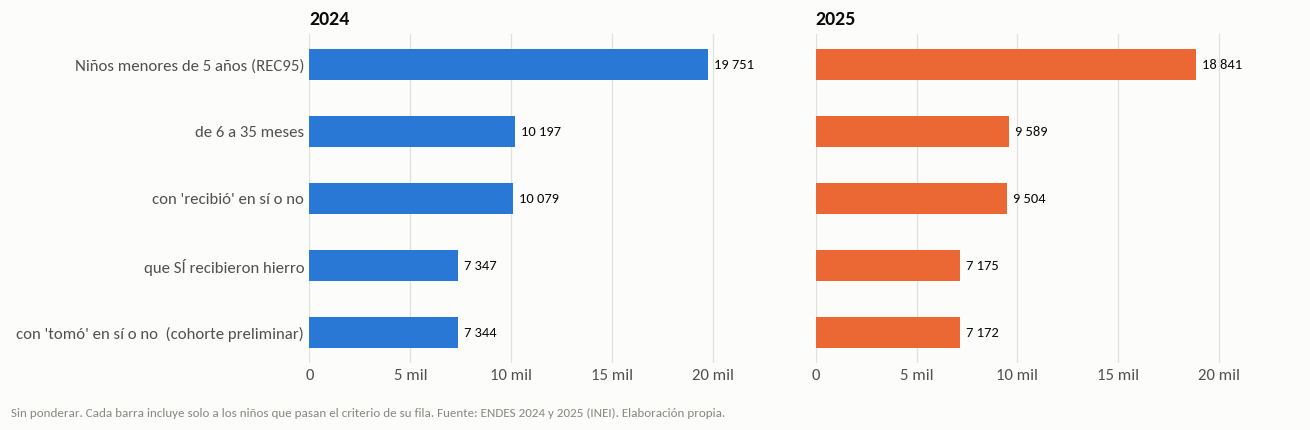

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import graficos as g

fig, axs = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, (anio, c) in zip(axs, ((2024, c24), (2025, c25))):
    pasos = list(c.index)[::-1]
    n = c["niños"].values[::-1]
    y = np.arange(len(pasos))
    ax.barh(y, n, height=0.46, color=g.COLOR_ANIO[anio], zorder=2)
    for yi, ni in zip(y, n):
        ax.text(ni + 300, yi, f"{ni:,}".replace(",", " "), va="center", fontsize=9.5, color=g.TINTA)
    ax.set_yticks(y)
    ax.set_yticklabels([p.replace("…", "") for p in pasos])
    ax.set_xlim(0, 24000)
    ax.set_xticks([0, 5000, 10000, 15000, 20000])
    ax.set_title(str(anio))
    g.rejilla(ax, "x")
    ax.xaxis.set_major_formatter(lambda v, p: f"{v/1000:.0f} mil" if v else "0")
g.pie(fig, "Sin ponderar. Cada barra incluye solo a los niños que pasan el criterio de su fila. Fuente: ENDES 2024 y 2025 (INEI). Elaboración propia.")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 6. Guardar la tabla y su diccionario
Se guardan las dos tablas y se genera el diccionario a partir de **una única lista** de columnas. Si el código y el diccionario no coincidieran, el cuaderno se detiene con un error.

In [9]:
COLUMNAS = [
    ("anio", "Año de la encuesta", "Año del archivo de origen"),
    ("caseid", "Identificador anónimo de la madre en los microdatos públicos de ENDES", "CASEID"),
    ("idx_nino", "Número de orden del niño dentro de la madre", "IDX95 (REC95)"),
    ("edad_meses", "Edad del niño en meses, calculada: fecha de entrevista − fecha de nacimiento", "V008 − B3"),
    ("edad_meses_hw1", "Edad en meses registrada en la medición de anemia (control de la anterior)", "HW1 (REC44)"),
    ("edad_discrepa", "Verdadero si las dos edades difieren en más de 1 mes", "Derivada"),
    ("banda_edad", "Banda de edad: 0-5, 6-11, 12-23, 24-35, 36-59 meses", "Derivada de edad_meses"),
    ("area", "Urbano o rural", "V025 (REC0111)"),
    ("departamento_cod", "Código de departamento (1 a 25)", "V024 (REC0111)"),
    ("departamento", "Nombre del departamento", "V024 (REC0111)"),
    ("region_natural", "Lima Metropolitana, Resto Costa, Sierra o Selva", "SREGION (REC91)"),
    ("altitud_msnm", "Altitud del conglomerado en metros", "V040 (REC0111)"),
    ("conglomerado", "Unidad primaria de muestreo (conglomerado). Idéntico a V001 y a HV001 en los datos", "V021 (REC0111)"),
    ("estrato", "Estrato del diseño muestral. Idéntico a HV022 en los datos", "V022 (REC0111)"),
    ("hhid", "Identificador del hogar en los microdatos públicos de ENDES", "HHID (REC0111)"),
    ("factor_expansion_crudo", "Factor MUJER sin transformar; el peso es este valor / 1 000 000 (ficha técnica). Se usa para indicadores del cuestionario individual", "V005 (REC0111)"),
    ("factor_hogar_crudo", "Factor HOGAR sin transformar; el peso es este valor / 1 000 000. La ficha técnica lo indica para anemia y desnutrición en menores de 5 años", "HV005 (RECH0)"),
    ("recibio_jarabe", "Recibió hierro en jarabe del MINSA en los últimos 12 meses (1 sí, 0 no, vacío = no sabe o no se preguntó)", "S465DB_A"),
    ("recibio_gotas", "Ídem, en gotas", "S465DB_B"),
    ("recibio_polvo", "Ídem, en polvo (micronutrientes)", "S465DB_C"),
    ("recibio_otra", "Ídem, otra presentación", "S465DB_D"),
    ("recibio_estado", "Resumen: sí, no, no sabe o vacío", "Derivada de S465DB_A a D"),
    ("recibio_12m", "1 si recibió alguna presentación; 0 si ninguna; vacío si no sabe o no se preguntó", "Derivada de S465DB_A a D"),
    ("tomo7_jarabe", "Tomó hierro en jarabe en los últimos 7 días (1 sí, 0 no, vacío = no sabe)", "S465EA"),
    ("tomo7_gotas", "Ídem, en gotas", "S465EC"),
    ("tomo7_polvo", "Ídem, en polvo (micronutrientes)", "S465EB"),
    ("tomo7_otra", "Ídem, otra presentación", "S465ED"),
    ("tomo_estado", "Resumen: sí, no, no sabe o vacío", "Derivada de S465EA a ED"),
    ("tomo_7d", "1 si tomó alguna presentación en los últimos 7 días; 0 si ninguna; vacío si no sabe o no se preguntó", "Derivada de S465EA a ED"),
    ("control_cred_alguno", "Le hicieron algún control de crecimiento y desarrollo (1 sí, 0 no)", "S466"),
    ("controles_cred_acum", "Cantidad de controles de crecimiento (parece acumulada desde el nacimiento; ver cuaderno 02). 98 y valores fuera de 0-40 quedan vacíos", "S466C"),
    ("razon_no_recibio_cod", "Código de por qué no recibió hierro del MINSA (1 no le dijeron, 2 se acabó, 3 por la edad, 4 no tiene anemia, 5 consumió por seis meses, 6 no acude al MINSA, 96 otra)", "Q465DF"),
    ("razon_no_consumo_cod", "Letras de las razones por las que no consumió todo el hierro recibido (puede haber varias). Se pregunta cuando la cantidad consumida en 12 meses es MENOR que la recibida (cuestionario 465DI); NO está ligada a la última semana", "Q465DJ"),
    ("razon_estomago", "Razón: le dolía el estómago (1 sí, 0 no, vacío = no se preguntó)", "Q465DJ, letra A"),
    ("razon_diarrea", "Razón: le causó diarrea", "Q465DJ, letra B"),
    ("razon_estrenimiento", "Razón: le causó estreñimiento", "Q465DJ, letra C"),
    ("razon_sabor", "Razón: el sabor es desagradable", "Q465DJ, letra D"),
    ("razon_dientes", "Razón: le tiñó los dientes", "Q465DJ, letra E"),
    ("razon_orientacion", "Razón: la orientación a la madre no fue adecuada", "Q465DJ, letra F"),
    ("razon_inicio_suplementacion", "Código G: inició suplementación o es continuador(a). NO es una razón de no consumo", "Q465DJ, letra G"),
    ("razon_olvido", "Razón: se olvidó de darle", "Q465DJ, letra H"),
    ("razon_otra", "Razón: otra", "Q465DJ, letra X"),
    ("nivel_anemia_minsa", "Nivel de anemia según RM 363-2022-MINSA (1 grave, 2 moderada, 3 leve, 4 sin anemia)", "HW57 (REC44)"),
    ("nivel_anemia_oms", "Nivel de anemia según la nueva directriz OMS 2024 / RM 251-2024-MINSA", "HW57A (REC44)"),
    ("anemia_minsa", "1 si tiene anemia (cualquier grado) según MINSA 2022; 0 si no", "Derivada de HW57"),
    ("anemia_oms", "1 si tiene anemia (cualquier grado) según OMS 2024; 0 si no", "Derivada de HW57A"),
    ("hb_ajustada_minsa_gdl", "Hemoglobina ajustada por altitud (g/dl), criterio MINSA 2022", "HW56 / 10"),
    ("hb_ajustada_oms_gdl", "Hemoglobina ajustada por altitud (g/dl), criterio OMS 2024", "HW56A / 10"),
    ("en_universo_6_35", "Verdadero si el niño tiene de 6 a 35 meses", "Derivada de edad_meses"),
    ("en_cohorte_modelo", "Verdadero si está en el universo, SÍ recibió hierro y tiene respuesta clara sobre si lo tomó (cohorte PRELIMINAR)", "Derivada"),
]

nombres_doc = [c[0] for c in COLUMNAS]
for a, d in tablas.items():
    faltan = set(d.columns) - set(nombres_doc)
    sobran = set(nombres_doc) - set(d.columns)
    assert not faltan and not sobran, f"{a}: columnas sin documentar {faltan} / documentadas que no existen {sobran}"
    assert list(d.columns) == nombres_doc, f"{a}: el orden de las columnas no coincide con el diccionario"

SALIDA.mkdir(exist_ok=True)
for a, d in tablas.items():
    d.to_csv(SALIDA / f"tabla_nino_{a}.csv", index=False, encoding="utf-8")
    print(f"Guardada: datos_procesados/tabla_nino_{a}.csv  ({len(d)} filas, {d.shape[1]} columnas)")

lineas = [
    "# Diccionario de la tabla del niño (`tabla_nino_2024.csv` y `tabla_nino_2025.csv`)",
    "",
    "Generado automáticamente por `analisis/03_union_y_limpieza.ipynb`. **No editar a mano:** si algo cambia, se corrige el cuaderno y se vuelve a ejecutar.",
    "",
    "Una fila por niño menor de 5 años de ENDES. Códigos de faltante: celda vacía (no hay ceros ni 9s inventados).",
    "Todas las variables de hierro y anemia son autorreporte o medición de la encuesta; ver limitaciones en `docs/registro_decisiones_analisis.md`.",
    "",
    "| Columna | Qué es | Fuente en ENDES |",
    "|---|---|---|",
]
lineas += [f"| `{n}` | {desc} | {fuente} |" for n, desc, fuente in COLUMNAS]

lineas += ["", "## Qué se excluyó y por qué (cohorte preliminar del modelo)", "",
           "Nadie se borra de la tabla: los niños excluidos siguen en ella, marcados con `en_universo_6_35` y `en_cohorte_modelo`. Pasos (niños sin ponderar):", "",
           "| Paso | Niños 2024 | Niños 2025 |", "|---|---|---|"]
for paso in c24.index:
    n24, n25 = f"{c24.loc[paso, 'niños']:,}".replace(",", " "), f"{c25.loc[paso, 'niños']:,}".replace(",", " ")
    lineas.append(f"| {paso.replace('…', '')} | {n24} | {n25} |")
lineas += [
    "",
    "- **Menores de 6 meses y de 36 meses o más:** fuera del universo del proyecto (6 a 35 meses).",
    "- **Respuesta 'no sabe' o vacía en 'recibió' o 'tomó':** se excluyen de la cohorte; **no se imputan**.",
    "- **No recibieron hierro del MINSA:** no entran a la cohorte del modelo (la pregunta de 'tomó' se usa solo entre quienes recibieron), pero sí cuentan en las cifras ponderadas de 'recibió'.",
    "",
    "## Limitaciones que hay que tener presentes",
    "",
    "1. **Autorreporte:** 'recibió' y 'tomó' son lo que declara la madre o cuidadora; dependen de su recuerdo. La anemia, en cambio, es una medición de hemoglobina.",
    "2. **Ventanas de tiempo distintas:** 'recibió' cubre los últimos **12 meses**; 'tomó', los últimos **7 días**. No miden adherencia en sentido estricto.",
    "3. **'No tomó' no es abandono:** incluye a quien ya terminó su esquema o aún no inicia el siguiente.",
    "4. **Solo hierro entregado por el MINSA:** las preguntas se refieren al hierro entregado por el MINSA; no se verificó que capten el hierro comprado por cuenta propia.",
    "5. **Universo:** la tabla contiene a los hijos menores de 5 años de mujeres entrevistadas (REC95). La anemia oficial se calcula con todos los niños de las viviendas visitadas (RECH6); por eso las cifras de anemia se calculan aparte (cuaderno 04).",
    "6. **Razones de no consumo (`razon_*`):** se preguntan cuando lo consumido es **menor** que lo recibido en 12 meses; **no** se refieren a la última semana. Son de respuesta múltiple y el código G no es una razón.",
    "7. **Letras de presentaciones:** las letras A a D **no significan lo mismo** en 'recibió' (`S465DB_*`) y en 'tomó' (`S465E*`); se emparejan por nombre, no por letra.",
    "8. **Edad:** se calcula como fecha de entrevista menos fecha de nacimiento (cobertura completa). `HW1` (edad de la medición de anemia) falta en muchos niños y se usa solo como control.",
    "9. **Factores de expansión:** las columnas `factor_*_crudo` vienen multiplicadas por 1 000 000; el peso real es el valor dividido entre 1 000 000. Para anemia corresponde el factor hogar y para hierro se usó el factor mujer (la ficha técnica no fija el del hierro).",
    "10. **Cohorte para el modelo:** es **preliminar**. La etiqueta 'no tomó' cambia de frecuencia entre 2024 y 2025 (ver cuaderno 04); validar con el asesor de salud antes de fijarla.",
]
(DOCS / "diccionario_tabla_nino.md").write_text("\n".join(lineas) + "\n", encoding="utf-8")
print("Guardado: docs/diccionario_tabla_nino.md")

Guardada: datos_procesados/tabla_nino_2024.csv  (19751 filas, 50 columnas)
Guardada: datos_procesados/tabla_nino_2025.csv  (18841 filas, 50 columnas)
Guardado: docs/diccionario_tabla_nino.md


## 7. Verificación: ¿otra persona obtendría lo mismo?
El plan dice que el trabajo está listo cuando Jose carga la tabla y obtiene los **mismos totales**. Releemos los archivos recién guardados, como lo haría él, y comparamos con lo calculado aquí y con el cuaderno 02.

In [10]:
verificacion = []
for a in (2024, 2025):
    leida = pd.read_csv(SALIDA / f"tabla_nino_{a}.csv", low_memory=False)
    verificacion.append({
        "año": a,
        "filas": len(leida),
        "6 a 35 meses": int(leida["en_universo_6_35"].sum()),
        "cohorte preliminar": int(leida["en_cohorte_modelo"].sum()),
        "% tomó 7d en la cohorte": round(100 * leida.loc[leida["en_cohorte_modelo"], "tomo_7d"].mean(), 1),
    })
ver = pd.DataFrame(verificacion).set_index("año")
print(ver.to_string())

# Cifras que dio el cuaderno 02 (cohorte preliminar y % que tomó, sin ponderar)
esperado = {2024: (7344, 40.4), 2025: (7172, 45.6)}
for a, (n, p) in esperado.items():
    ok = (int(ver.loc[a, "cohorte preliminar"]) == n) and (abs(ver.loc[a, "% tomó 7d en la cohorte"] - p) < 0.05)
    print(f"{a}: coincide con el cuaderno 02 ({n} niños; {p} %): {'SÍ' if ok else 'NO  <-- revisar'}")

      filas  6 a 35 meses  cohorte preliminar  % tomó 7d en la cohorte
año                                                                   
2024  19751         10197                7344                     40.4
2025  18841          9589                7172                     45.6
2024: coincide con el cuaderno 02 (7344 niños; 40.4 %): SÍ
2025: coincide con el cuaderno 02 (7172 niños; 45.6 %): SÍ


## 8. Conclusiones

### Lo que quedó hecho
1. **Las uniones no pierden niños:** las 10 uniones (5 por año) conservan los 19 751 niños de 2024 y los 18 841 de 2025, sin ningún niño sin pareja.
2. **Las comprobaciones críticas dan 0:** sin llaves repetidas, sin códigos inesperados en las preguntas de hierro, sin respuestas "a medias", sin edades fuera de rango y sin niños sin diseño muestral.
3. **La tabla del niño tiene 50 columnas** y su diccionario se generó del mismo código (`docs/diccionario_tabla_nino.md`), así que no pueden desalinearse.
4. **Se agregaron el identificador del hogar y el factor hogar (`HV005`)** porque la ficha técnica de ENDES indica ese factor para la anemia en menores de 5 años. La escala (dividir entre 1 000 000) también está en la ficha técnica.
5. **Los totales coinciden con el cuaderno 02** al releer los archivos guardados: cohorte preliminar de **7 344 niños (2024)** y **7 172 (2025)**.

### Cómo se llega a la cohorte preliminar (trazabilidad)
| Paso | 2024 | 2025 |
|---|---|---|
| Niños de 6 a 35 meses | 10 197 | 9 589 |
| Sin respuesta clara sobre si recibieron (no sabe o vacío) | −118 | −85 |
| No recibieron hierro del MINSA | −2 732 | −2 329 |
| Recibieron pero sin respuesta clara sobre si lo tomaron | −3 | −3 |
| **Cohorte preliminar** | **7 344** | **7 172** |

### Hallazgos que cambian cómo se interpreta
- **Las razones de no consumo no explican la última semana.** `Q465DJ` se pregunta (según el cuestionario) cuando la cantidad consumida en los últimos 12 meses es **menor** que la recibida. En los datos: la responden el 72,0 % (2024) y el 73,6 % (2025) de los que recibieron hierro, y **aparece incluso en niños que sí tomaron hierro la semana pasada**. Por tanto, esas razones describen por qué no se terminó lo recibido, **no** por qué un niño no lo tomó en los últimos 7 días. Esto importa para la segunda pregunta del asistente (las razones) y para cualquier cifra del pitch que las use: hay que presentarlas como "razones por las que no se consumió todo lo recibido".
- **Entre 17,5 % (2024) y 18,3 % (2025) de los niños de 6 a 35 meses que dicen no haber recibido hierro del MINSA, lo tomaron igual la última semana** (477 y 427 niños, sin ponderar). Puede ser hierro comprado u otra fuente. Esos niños quedan fuera de la cohorte por la definición actual.
- **Hay una medida alternativa de consumo que hoy no usamos:** el cuestionario pregunta cuántos frascos o sobres se **recibieron y cuántos se consumieron** en 12 meses (`S465DD_*`). Podría dar una etiqueta de adherencia menos sensible al momento de la entrevista que "tomó en 7 días". Es una opción para discutir con Jose, no una decisión.
- **La edad calculada y la directa discrepan en más de 1 mes en pocos casos** (29 en 2024 y 16 en 2025 dentro de 6 a 35 meses). Se mantiene la calculada; los casos quedan marcados en `edad_discrepa`.

### Límites y supuestos de este cuaderno
- **Cohorte preliminar:** niños de 6 a 35 meses que recibieron hierro y tienen respuesta clara sobre si lo tomaron. Los criterios están en la sección 5.
- **Niños que no recibieron hierro del MINSA pero sí lo tomaron** (17,5 % en 2024 y 18,3 % en 2025 de los que no recibieron): quedan fuera de la cohorte y están documentados.
- **Adherencia:** existe una medida alternativa (cantidad recibida frente a consumida, `S465DD_*`) que no se evaluó aquí.
- **Razones de no consumo:** se interpretan como "razones por las que no se consumió todo lo recibido en 12 meses", no como razones de la última semana.
- **Tablas procesadas:** no se suben al repositorio; se regeneran ejecutando este cuaderno.

**Siguiente cuaderno:** `04_cifras_ponderadas`, que calcula las cifras con el diseño muestral (factor, estrato y conglomerado) e intervalos de confianza.